# ECG Signal Pre-processing

In this work, an ECG recording (6 channels, 30 seconds) is cleaned with the
**4 standard pre-processing steps**:

1. **Recording spike removal** (artifacts of great amplitude)
2. **Low-pass filtering**
3. **Power-line interference filtering**
4. **Baseline wander and offset removal**

Steps 2 to 4 are carried out in two ways: **Method A** in the *frequency domain* and
**Method B** in the *time domain*. Before steps 2 to 4, **padding** is added to every
signal to avoid distortions at the start and the end of the recording.

Note on channel numbering: Python counts from 0, so `ecg[0]` is **Ch1** and `ecg[5]` is **Ch6**.

## 1. Libraries

In [1]:
import numpy as np                            # maths
import matplotlib.pyplot as plt               # plots
import h5py                                   # opens the .mat file
from scipy.ndimage import median_filter       # median filter
from scipy.ndimage import uniform_filter1d    # moving average
from scipy.signal import find_peaks           # finds heartbeats

plt.rcParams["axes.grid"] = True

## 2. Import of the file and check of the keys

The `.mat` file is saved in MATLAB version 7.3, so it is opened with `h5py`.
(Older `.mat` files can be opened with `scipy.io.loadmat`.)

In [2]:
file = h5py.File("ecgConditioningExample.mat", "r")
print("Keys:", list(file.keys()))

ecg = file["ecg"][:]          # the signal: 6 channels x 30000 samples
fs = file["fs"][0][0]         # the sampling frequency
file.close()

print("ecg shape:", ecg.shape)

Keys: ['ecg', 'fs']
ecg shape: (6, 30000)


## 3. Sampling frequency and Nyquist frequency

* The **sampling frequency** `fs` is the number of samples recorded per second.
* The **Nyquist frequency** is `fs / 2`. It is the highest frequency that can be seen in the signal.

In [3]:
n_samples = ecg.shape[1]
nyquist = fs / 2
duration = n_samples / fs
# time of every sample, in seconds
t = np.arange(n_samples) / fs
ch_names = ["Ch1", "Ch2", "Ch3", "Ch4", "Ch5", "Ch6"]

print("Sampling frequency:", fs, "Hz")
print("Nyquist frequency :", nyquist, "Hz")
print("Duration          :", duration, "s")

Sampling frequency: 1000.0 Hz
Nyquist frequency : 500.0 Hz
Duration          : 30.0 s


The Nyquist frequency (500 Hz) is much higher than the main ECG band of **0.5 to 40 Hz**,
so all frequencies needed for the ECG are recorded and this recording can be used.

## 4. Check of the channels

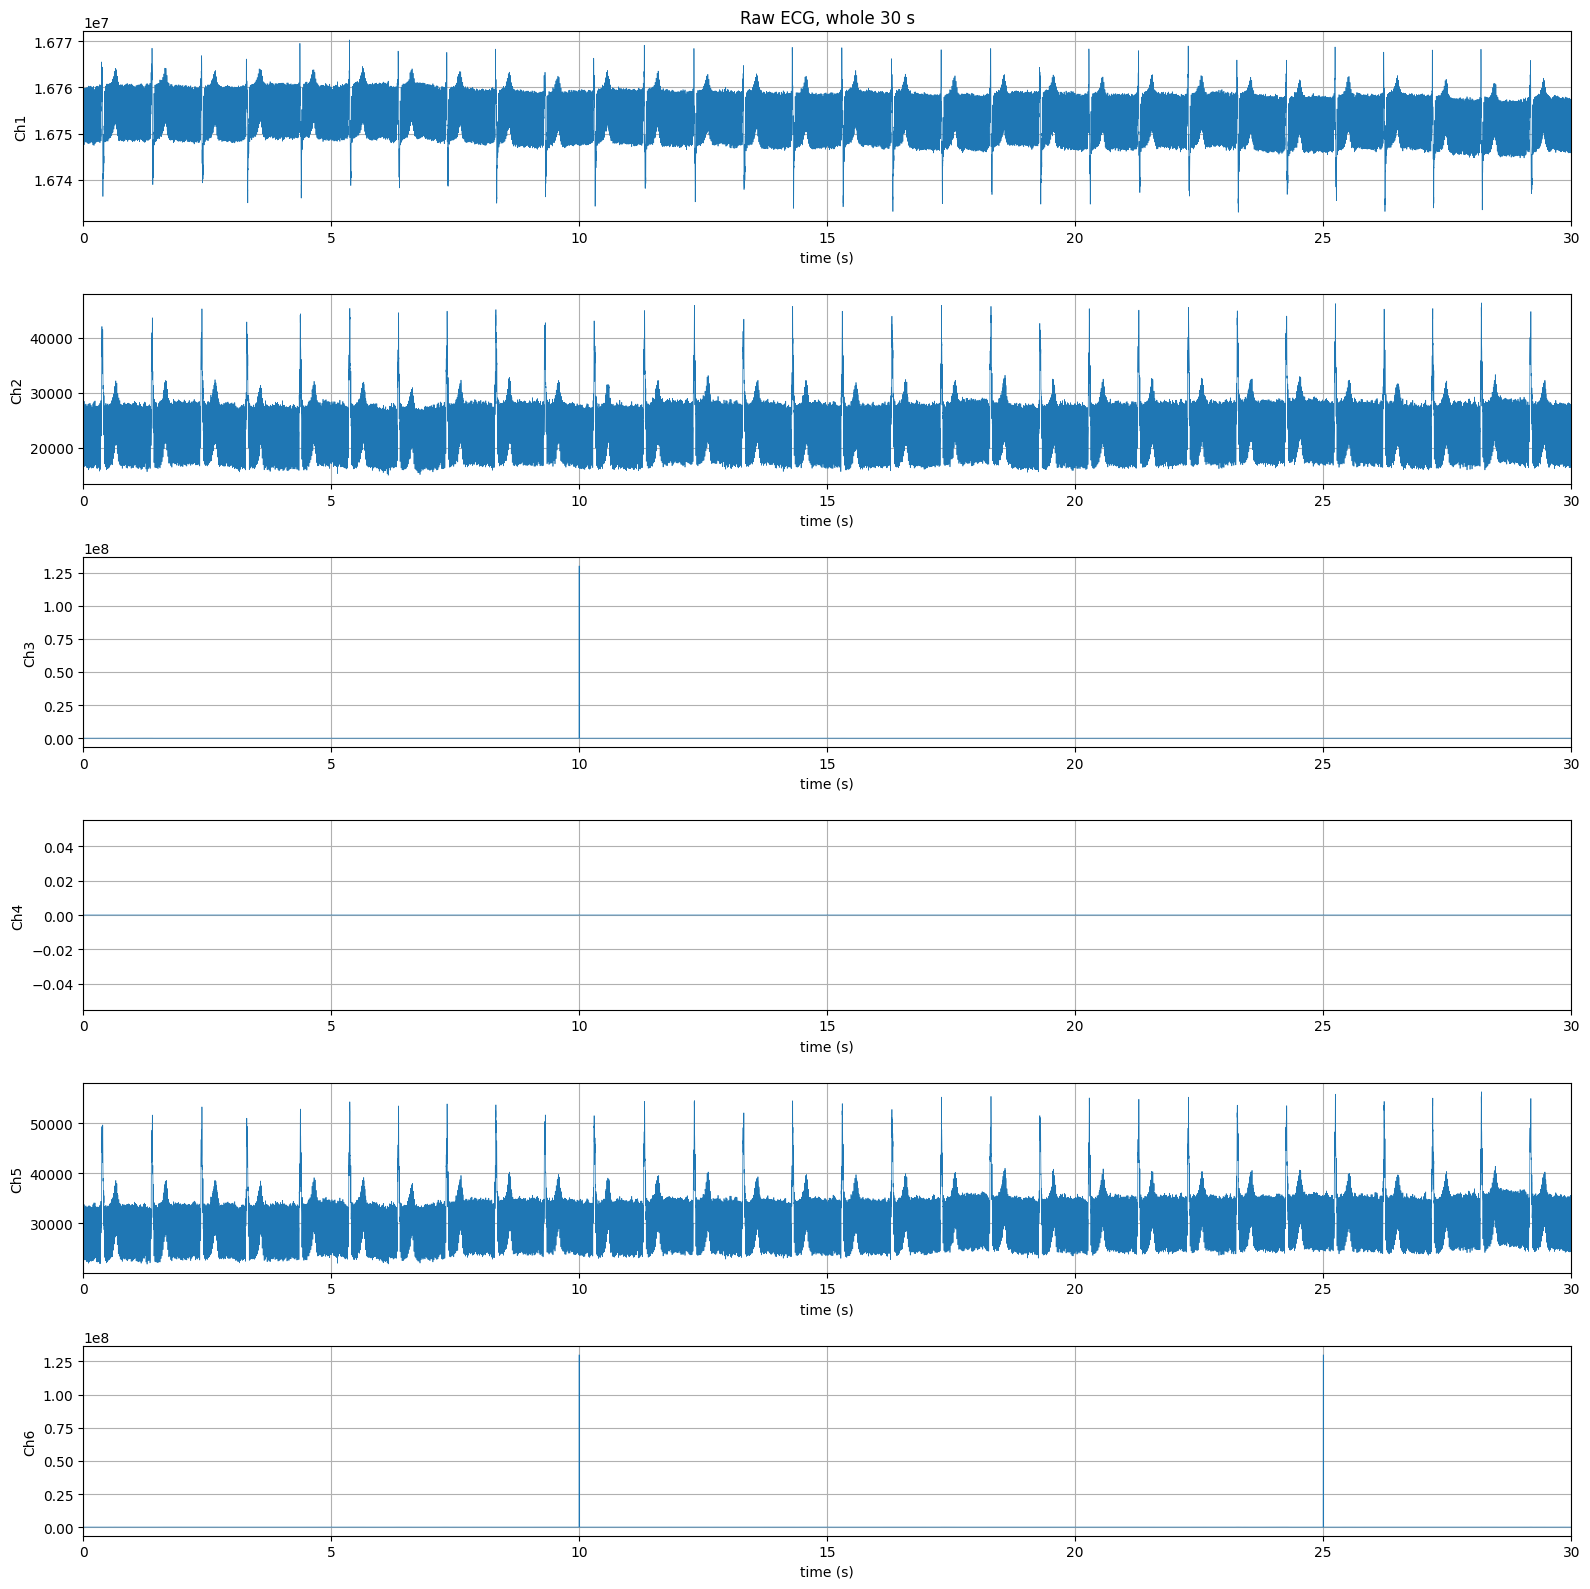

In [4]:
fig, axes = plt.subplots(6, 1, figsize=(16, 16))
for i in range(6):
    axes[i].plot(t, ecg[i], linewidth=0.5)
    axes[i].set_ylabel(ch_names[i])
    axes[i].set_xlabel("time (s)")            # time axis on every plot
    axes[i].set_xlim(0, 30)
axes[0].set_title("Raw ECG, whole 30 s")
plt.tight_layout()
plt.show()

| Channel | Observation |
|---------|-------------|
| Ch1 | values around 16 750 000, so a large **offset** is present |
| Ch3, Ch6 | a few values of 130 000 000, so **recording spikes** are present |
| Ch4 | always 0, so the channel is **not connected** |
| all | a very "thick" line, caused by **power-line noise** (50 Hz) |

## 5. Detection of a channel that is not connected

A channel that is not connected is recorded as a **flat line**, so its standard deviation is 0.

In [5]:
for i in range(6):
    if np.std(ecg[i]) == 0:
        print(ch_names[i], "NOT CONNECTED")
    else:
        print(ch_names[i], "connected")

Ch1 connected
Ch2 connected
Ch3 connected
Ch4 NOT CONNECTED
Ch5 connected
Ch6 connected


Ch4 is not connected, so it is skipped in all following steps.
The connected channels are `[0, 1, 2, 4, 5]` (Ch1, Ch2, Ch3, Ch5 and Ch6).

## 6. Fourier transform

The Fourier transform shows **which frequencies** are present in a signal.
`np.fft.rfft` turns the 30 000 samples of the signal into a list of values (one value for
every frequency). The Fourier transform of Ch2 is shown twice: first over the **sample number**
of this list, then over the **frequency** in Hz.

### 6.1 Fourier transform of Ch2 over the sample number

number of FFT values: 15001


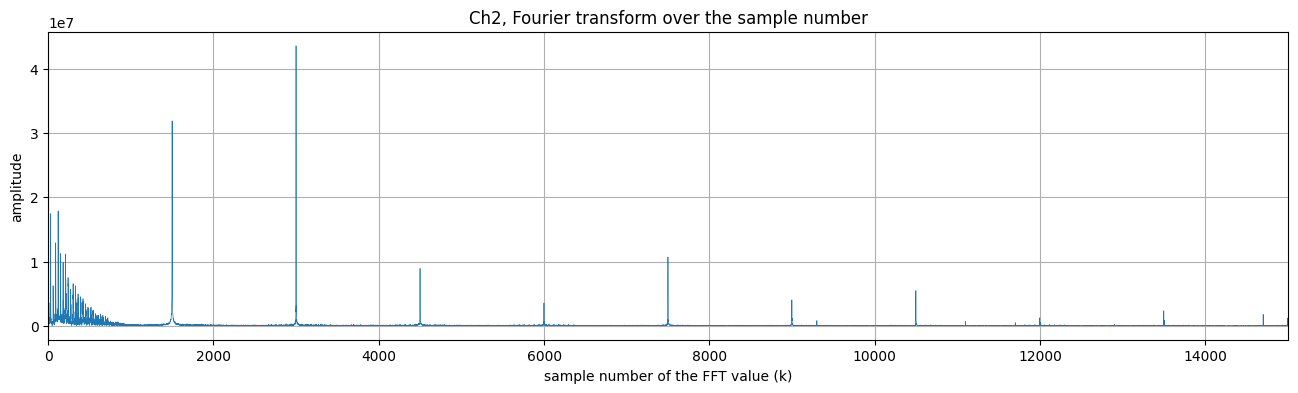

In [6]:
x = ecg[1]                                    # Ch2
X = np.fft.rfft(x - np.mean(x))               # Fourier transform
# sample number of every FFT value: 0, 1, 2, ...
k = np.arange(len(X))

print("number of FFT values:", len(X))

plt.figure(figsize=(16, 4))
plt.plot(k, np.abs(X), linewidth=0.5)
# all values: k = 0 to 15000
plt.xlim(0, len(X))
plt.xlabel("sample number of the FFT value (k)")
plt.ylabel("amplitude")
plt.title("Ch2, Fourier transform over the sample number")
plt.show()

The sample number `k` is not yet a frequency. It is converted to a frequency with:

$$ f = k \cdot \frac{f_s}{N} = k \cdot \frac{1000}{30000} = \frac{k}{30} \ \text{Hz} $$

where `N` = 30 000 is the number of samples of the signal. So one step of `k` is 1/30 Hz
(about 0.033 Hz). For example, the peak at **k = 1500** is at 1500 / 30 = **50 Hz**, and the peak
at **k = 3000** is at **100 Hz**. The function `np.fft.rfftfreq` does this conversion.

### 6.2 Fourier transform of Ch2 over the frequency

k = 1500 is 50.0 Hz
k = 3000 is 100.0 Hz
k = 15000 is 500.0 Hz (the Nyquist frequency)


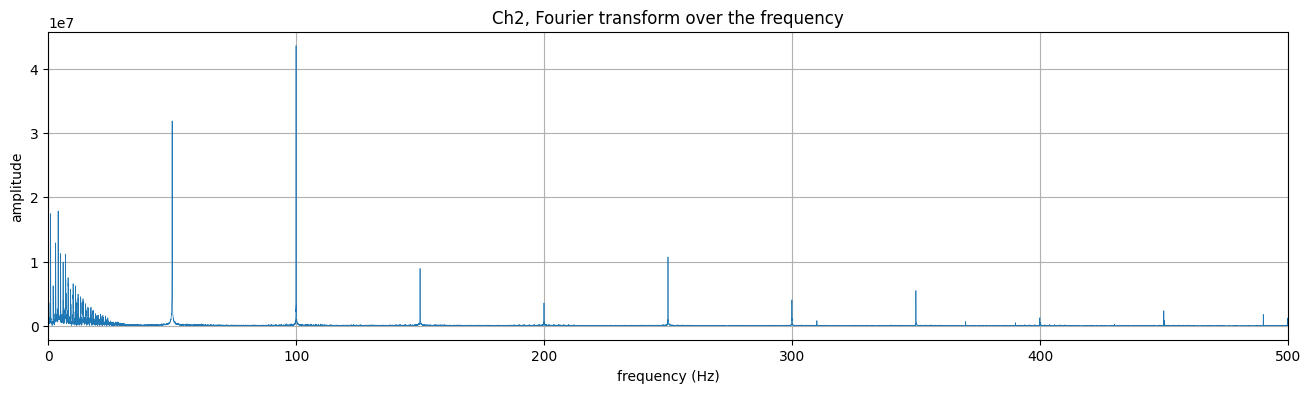

In [7]:
# frequency of every FFT value: f = k * fs / N
f = np.fft.rfftfreq(len(x), 1 / fs)

print("k = 1500 is", f[1500], "Hz")
print("k = 3000 is", f[3000], "Hz")
print("k = 15000 is", f[15000], "Hz (the Nyquist frequency)")

plt.figure(figsize=(16, 4))
plt.plot(f, np.abs(X), linewidth=0.5)
# all positive frequencies: 0 to 500 Hz
plt.xlim(0, nyquist)
plt.xlabel("frequency (Hz)")
plt.ylabel("amplitude")
plt.title("Ch2, Fourier transform over the frequency")
plt.show()

The two plots are the same; only the x-axis is different. All positive frequencies are shown:
sample number 0 to 15 000 is 0 to 500 Hz (the Nyquist frequency).

* **0.5 to 40 Hz:** the heartbeat
* **sharp peaks at 50, 100, 150 Hz and further multiples of 50 Hz up to 450 Hz:** power-line noise and its harmonics
* **very small values at high frequencies:** muscle noise (on this scale it is almost not visible)

## 7. The four kinds of ECG noise

| Noise | Cause | Frequency |
|-------|-------|-----------|
| **Baseline Wander (BW)** | breathing, movement | very low, below 0.5 Hz |
| **Power Line Interference (PLI)** | mains electricity | 50 Hz (60 Hz in America) and 100, 150 ... Hz |
| **Muscle / EMG noise** | muscle activity | high, about 20 to 500 Hz |
| **Motion Artifacts (MA) / Electrode Movement (EM)** | movement of the electrode | 1 to 10 Hz (the same band as the ECG, so it is the hardest to remove) |

## 8. Step 1: Recording spike removal

A **recording spike** is a very large value that lasts only a few samples. It does not come
from the heart, but from the recording system (for example an amplifier overload or a knock on the cable).

This step is the same for Method A and Method B, and it must be done **first**,
because a spike would ruin every filter applied after it.

The step has two parts: **detection** (which samples are spikes?) and **repair** (which value is used instead?).

### 8.1 Detection: the percentile method

A spike is a value that lies **far outside the normal range** of the channel. The normal range is
found with two **percentiles**:

* the **1st percentile** (`low`): 1 % of all samples are lower than this value
* the **99th percentile** (`high`): 1 % of all samples are higher than this value

So 98 % of all samples lie between `low` and `high`. A few spike samples have no influence on
these two values, because they are far fewer than 1 % of the samples.

The size of the normal range is `width = high - low`. A sample is marked as a spike when it lies
**more than 5 widths** above `high` or below `low`:

```
spike if   x > high + 5 * width   or   x < low - 5 * width
```

The limits are shown below for Ch6, which contains two spikes:

In [8]:
x = ecg[5]                                    # Ch6

# 1 % of the samples are lower
low = np.percentile(x, 1)
# 1 % of the samples are higher
high = np.percentile(x, 99)
width = high - low                            # size of the normal range

upper_limit = high + 5 * width
lower_limit = low - 5 * width
is_spike = (x > upper_limit) | (x < lower_limit)

print("low (1st percentile)  :", round(low))
print("high (99th percentile):", round(high))
print("width                 :", round(width))
print("upper limit           :", round(upper_limit))
print("lower limit           :", round(lower_limit))
print()
print("largest normal sample :", round(np.max(x[~is_spike])))
print("smallest normal sample:", round(np.min(x[~is_spike])))
print("spike values          :", x[is_spike])
print()
spike_index = np.where(is_spike)[0]
print("spike sample numbers:", spike_index)
print("spike times (s)     :", t[spike_index])

low (1st percentile)  : 32327
high (99th percentile): 58112
width                 : 25785
upper limit           : 187039
lower limit           : -96599

largest normal sample : 66187
smallest normal sample: 31102
spike values          : [1.3e+08 1.3e+08 1.3e+08 1.3e+08 1.3e+08 1.3e+08 1.3e+08 1.3e+08]

spike sample numbers: [ 9999 10000 10001 10002 24999 25000 25001 25002]
spike times (s)     : [ 9.999 10.    10.001 10.002 24.999 25.    25.001 25.002]


**Why 5 widths?** In this recording, the normal samples (including the tops of the tall R-peaks)
lie at most about 0.4 widths outside the range from `low` to `high`, in every channel.
The spike samples lie more than 5 000 widths above `high`. A limit of 5 widths separates them
safely. For other recordings, this limit should be checked in the same way.

### 8.2 Repair: linear interpolation

The spike samples are replaced by **linear interpolation** between the
**last good sample before the spike** (start) and the **first good sample after the spike** (end).
In this way, the repaired samples follow the slope of the signal and no flat piece or jump is created.

The linear interpolation is calculated in three small steps:

1. the **start** sample and the **end** sample are found
2. the **step** is calculated: `step = (value at end - value at start) / (end - start)`
3. every spike sample gets the value `value at start + step * (distance from start)`

This is shown below for the first spike of Ch6 (samples 9999 to 10002):

In [9]:
# last good sample before the spike
start = 9998
# first good sample after the spike
end = 10003

step = (ecg[5, end] - ecg[5, start]) / (end - start)

print("value at start:", round(ecg[5, start]))
print("value at end  :", round(ecg[5, end]))
print("step          :", round(step, 1))
print()
for n in range(start + 1, end):
    print("sample", n, "->", round(ecg[5, start] + step * (n - start)))

value at start: 39112
value at end  : 43658
step          : 909.2

sample 9999 -> 40021
sample 10000 -> 40931
sample 10001 -> 41840
sample 10002 -> 42749


For all spikes of all channels, the same linear interpolation is done with the numpy function
`np.interp`. It interpolates linearly between the good samples and
returns the values at the spike positions:

```
ecg1[i, is_spike] = np.interp(t[is_spike], t[good], ecg[i, good])
```

* `t[good]` and `ecg[i, good]`: the known points (all good samples)
* `t[is_spike]`: the times where new values are needed (the spike samples)

The detection and the repair are now applied to all connected channels:

In [10]:
ecg1 = ecg.copy()                             # signals after step 1

for i in [0, 1, 2, 4, 5]:                     # all channels except Ch4
    low = np.percentile(ecg[i], 1)
    high = np.percentile(ecg[i], 99)
    width = high - low
    is_spike = (ecg[i] > high + 5 * width) | (ecg[i] < low - 5 * width)
    # True for the good samples
    good = ~is_spike

    # linear interpolation between the good samples around each spike
    ecg1[i, is_spike] = np.interp(t[is_spike], t[good], ecg[i, good])

    print(ch_names[i], "spike samples:", np.sum(is_spike))

Ch1 spike samples: 0
Ch2 spike samples: 0
Ch3 spike samples: 4
Ch5 spike samples: 0
Ch6 spike samples: 8


The samples of Ch6 around the first spike, before and after the repair.
Samples 9999 to 10002 are the spike; after the repair they are linearly interpolated
between sample 9998 and sample 10003.

In [11]:
print("sample   time (s)       before        after")
for n in range(9996, 10006):
    print(n, "  ", t[n], "  ", round(ecg[5, n]), "  ",
          round(ecg1[5, n]))

sample   time (s)       before        after
9996    9.996    34455    34455
9997    9.997    36973    36973
9998    9.998    39112    39112
9999    9.999    130000000    40021
10000    10.0    130000000    40931
10001    10.001    130000000    41840
10002    10.002    130000000    42749
10003    10.003    43658    43658
10004    10.004    40300    40300
10005    10.005    36932    36932


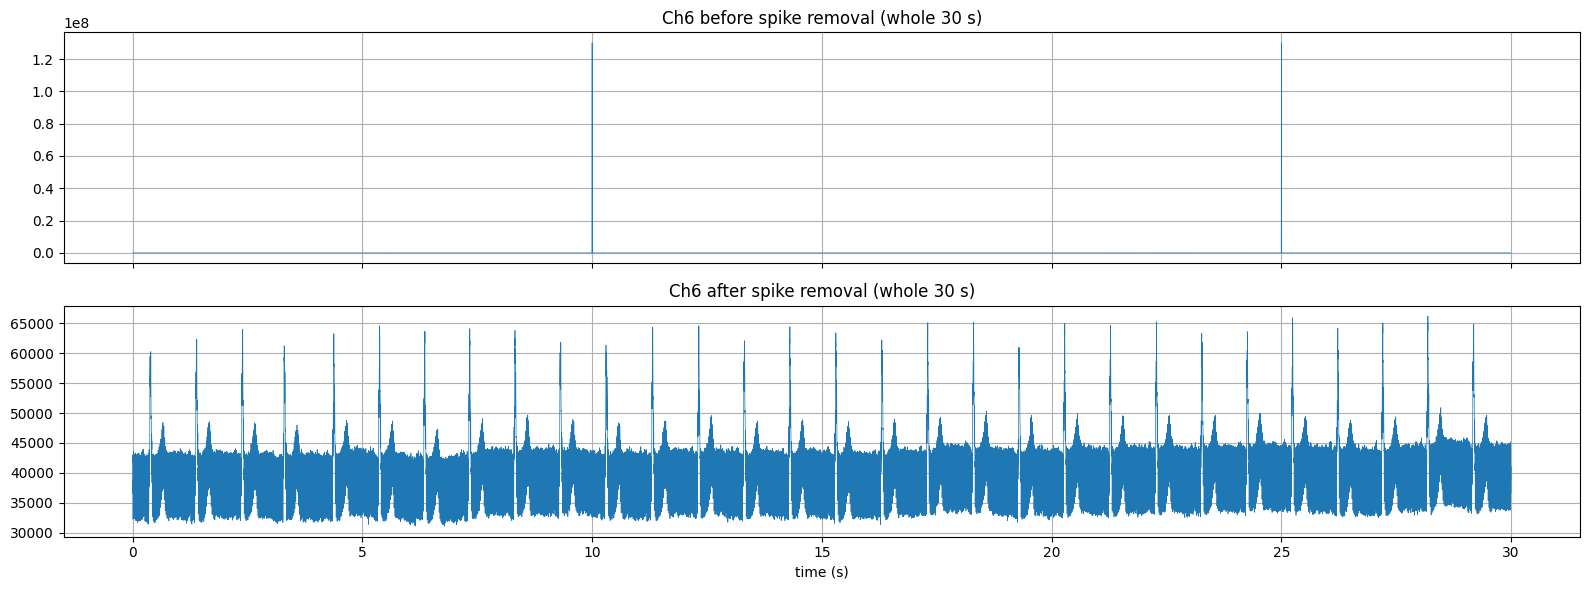

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
axes[0].plot(t, ecg[5], linewidth=0.5)
axes[0].set_title("Ch6 before spike removal (whole 30 s)")
axes[1].plot(t, ecg1[5], linewidth=0.5)
axes[1].set_title("Ch6 after spike removal (whole 30 s)")
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

## 9. Kernel sizes and padding

### 9.1 Choice of the kernel sizes

With fs = 1000 Hz, 1 sample = 1 ms. Every kernel size is selected from what the filter has to remove:

| Filter | Kernel size | Reason |
|--------|-------------|--------|
| Method B, step 2: low-pass (moving average) | 5 samples (5 ms) | frequencies above about 90 Hz are reduced and 200 Hz is removed completely, which is similar to the 100 Hz cut of Method A; the heartbeat (below 40 Hz) is almost not changed, while a larger kernel would flatten the sharp QRS |
| Method B, step 3: power-line (moving average) | 20 samples (20 ms) | exactly one 50 Hz wave (1000 / 50 = 20 samples), so the 50 Hz wave and all its harmonics (100, 150 ... Hz) average to 0; any other size would leave part of the noise |
| Method B, step 4: baseline (median filter) | 201 samples (200 ms) | a median filter removes every wave shorter than about half its window, so the QRS complex and the P wave (about 80 to 100 ms) are removed |
| Method B, step 4: baseline (median filter) | 601 samples (600 ms) | the T wave (about 150 to 250 ms) is also removed, while the window is still much shorter than the baseline wander (3 to 5 s), so only the slow baseline remains |
| Method A, steps 2 to 4 (FFT filters) | 2000 samples (2 s) | the FFT filters have no short window; the slowest wave that is changed is one wave of the lowest cut-off frequency, 0.5 Hz, which lasts 2 s |

Notes:
* The median filter sizes 201 and 601 are odd, so the window has one exact centre sample and the result is not shifted in time.
* The pair 200 ms and 600 ms is a well-known choice for baseline removal in the ECG literature (de Chazal et al., 2004).

**Why a median filter removes a wave:** the median is the middle value of the sorted window.
A wave that fills **less than half** of the window ends up at the top after sorting, so the median
is a baseline value and the wave is removed. The T wave (up to about 250 ms) is longer than half of
200 ms (100 ms), so it is not removed by the 201-sample filter, but it is shorter than half of
600 ms (300 ms), so it is removed by the 601-sample filter. The window is still much shorter than
the baseline wander (3 to 5 s), so the slow baseline is kept.

### 9.2 Padding

Every filter has a problem at the **start** and the **end** of a signal. A filter with a kernel
of K samples needs K/2 samples on each side of every sample.
At the edges these samples do not exist, so the result is distorted there (small ripples).

To avoid this, **padding** is added: extra samples are placed before the start and after the end,
the filters are applied, and the extra samples are removed again at the end.
The size of the padding is selected from the **kernel size**: at least K/2 samples are needed on each side.

| Method | Kernel size K | Padding K/2 |
|--------|---------------|-------------|
| Method A (frequency domain) | the FFT filters have no short window; the longest wave that is changed is one wave of the lowest cut-off frequency, 0.5 Hz, so K = 2 s = 2000 samples | 1000 samples (1 s) |
| Method B (time domain) | the largest window is the 600 ms median filter, so K = 601 samples | 300 samples (0.3 s) |

The padding is made by copying: the first samples of the signal are copied **in front** of the
signal, and the last samples are copied **after** the signal. Both padding sizes (1000 and 300)
are whole multiples of 20 samples (one 50 Hz wave), so the power-line wave continues smoothly at the edges.

In [13]:
# Method A: one wave of 0.5 Hz = 2000 samples
kernel_a = int(fs / 0.5)
# Method B: the 600 ms median filter = 601 samples
kernel_b = 601

pad_a = kernel_a // 2                         # 1000 samples
pad_b = kernel_b // 2                         # 300 samples

print("Method A: kernel size", kernel_a, "samples,",
      "padding", pad_a, "samples on each side")
print("Method B: kernel size", kernel_b, "samples,",
      "padding", pad_b, "samples on each side")

Method A: kernel size 2000 samples, padding 1000 samples on each side
Method B: kernel size 601 samples, padding 300 samples on each side


In [14]:
# length of a padded signal (Method A)
n_pad_a = n_samples + 2 * pad_a
# length of a padded signal (Method B)
n_pad_b = n_samples + 2 * pad_b
# time axis, starts at -1 s
t_pad_a = (np.arange(n_pad_a) - pad_a) / fs
# time axis, starts at -0.3 s
t_pad_b = (np.arange(n_pad_b) - pad_b) / fs

ecg1_pad_a = np.zeros((6, n_pad_a))
ecg1_pad_b = np.zeros((6, n_pad_b))
for i in [0, 1, 2, 4, 5]:                     # all channels except Ch4
    ecg1_pad_a[i] = np.concatenate(
        [ecg1[i, :pad_a], ecg1[i], ecg1[i, -pad_a:]])
    ecg1_pad_b[i] = np.concatenate(
        [ecg1[i, :pad_b], ecg1[i], ecg1[i, -pad_b:]])

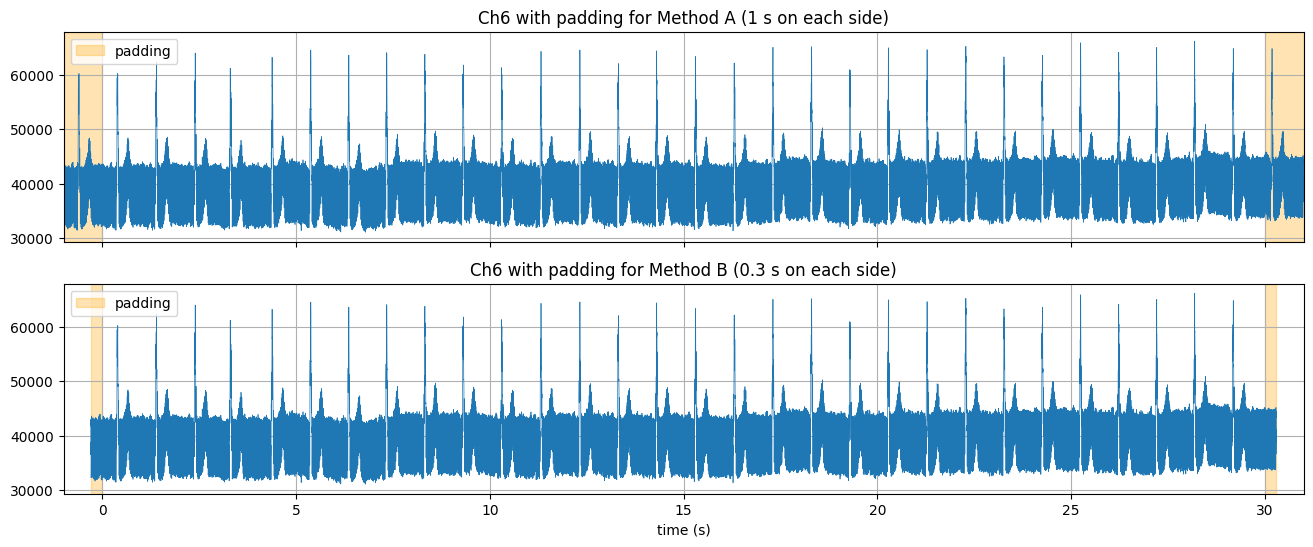

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
axes[0].plot(t_pad_a, ecg1_pad_a[5], linewidth=0.5)
axes[0].axvspan(-pad_a / fs, 0, color="orange", alpha=0.3,
                label="padding")
axes[0].axvspan(30, 30 + pad_a / fs, color="orange", alpha=0.3)
axes[0].set_title("Ch6 with padding for Method A (1 s on each side)")
axes[0].legend()
axes[1].plot(t_pad_b, ecg1_pad_b[5], linewidth=0.5)
axes[1].axvspan(-pad_b / fs, 0, color="orange", alpha=0.3,
                label="padding")
axes[1].axvspan(30, 30 + pad_b / fs, color="orange", alpha=0.3)
axes[1].set_title("Ch6 with padding for Method B (0.3 s on each side)")
axes[1].legend()
axes[1].set_xlim(-1, 31)
axes[1].set_xlabel("time (s)")
plt.show()

## 10. Method A: steps 2, 3 and 4 in the frequency domain

Every step follows the same idea: the signal is moved to the frequency domain,
some frequencies are set to 0, and the signal is moved back to the time domain.

| Step | Frequencies set to 0 |
|------|----------------------|
| 2. Low-pass | everything above 100 Hz |
| 3. Power-line | 49 to 51 Hz, 99 to 101 Hz, ... |
| 4. Offset and baseline | 0 Hz (offset) and everything below 0.5 Hz (wander) |

In [16]:
# the frequency of each FFT value
freqs = np.fft.rfftfreq(n_pad_a, 1 / fs)

# Step 2: low-pass filter
a2 = np.zeros((6, n_pad_a))
for i in [0, 1, 2, 4, 5]:
    X = np.fft.rfft(ecg1_pad_a[i])
    # everything above 100 Hz is deleted
    X[freqs > 100] = 0
    a2[i] = np.fft.irfft(X, n_pad_a)

# Step 3: power-line filter
a3 = np.zeros((6, n_pad_a))
for i in [0, 1, 2, 4, 5]:
    X = np.fft.rfft(a2[i])
    for h in range(50, 500, 50):              # 50, 100, 150, ... Hz
        # h - 1 to h + 1 Hz is deleted
        X[np.abs(freqs - h) <= 1] = 0
    a3[i] = np.fft.irfft(X, n_pad_a)

# Step 4: offset and baseline wander removal
a4 = np.zeros((6, n_pad_a))
for i in [0, 1, 2, 4, 5]:
    X = np.fft.rfft(a3[i])
    # 0 Hz = offset, below 0.5 Hz = wander
    X[freqs < 0.5] = 0
    a4[i] = np.fft.irfft(X, n_pad_a)

## 11. Method B: steps 2, 3 and 4 in the time domain

No Fourier transform is used here. The samples are processed directly with a sliding window.

| Step | Operation |
|------|-----------|
| 2. Low-pass | average of 5 neighbouring samples |
| 3. Power-line | average of 20 samples, which is exactly one 50 Hz wave, so the wave averages to 0 |
| 4. Offset and baseline | the mean is subtracted (offset), then a slow baseline found with median filters (200 ms, then 600 ms) is subtracted (wander) |

In [17]:
# Step 2: low-pass filter
b2 = np.zeros((6, n_pad_b))
for i in [0, 1, 2, 4, 5]:
    # average of 5 samples
    b2[i] = uniform_filter1d(ecg1_pad_b[i], 5)

# Step 3: power-line filter
b3 = np.zeros((6, n_pad_b))
for i in [0, 1, 2, 4, 5]:
    # average of 20 samples (one 50 Hz wave)
    b3[i] = uniform_filter1d(b2[i], 20)

# Step 4: offset and baseline wander removal
b4 = np.zeros((6, n_pad_b))
for i in [0, 1, 2, 4, 5]:
    x = b3[i] - np.mean(b3[i])                          # offset
    # 200 ms, then 600 ms
    baseline = median_filter(median_filter(x, 201), 601)
    b4[i] = x - baseline                                # wander

## 12. Removal of the padding

After all filters, the padding is cut away on both sides (1000 samples for Method A,
300 samples for Method B), so the signals have their original length again.

In [18]:
ecg_a = a4[:, pad_a:-pad_a]                   # final result of Method A
ecg_b = b4[:, pad_b:-pad_b]                   # final result of Method B

print("length after removing the padding:",
      ecg_a.shape[1], "and", ecg_b.shape[1], "samples")

length after removing the padding: 30000 and 30000 samples


## 13. All steps, one after the other

Ch6 is shown after every step. Left: Method A. Right: Method B.
The orange areas are the padding, which is removed at the end.

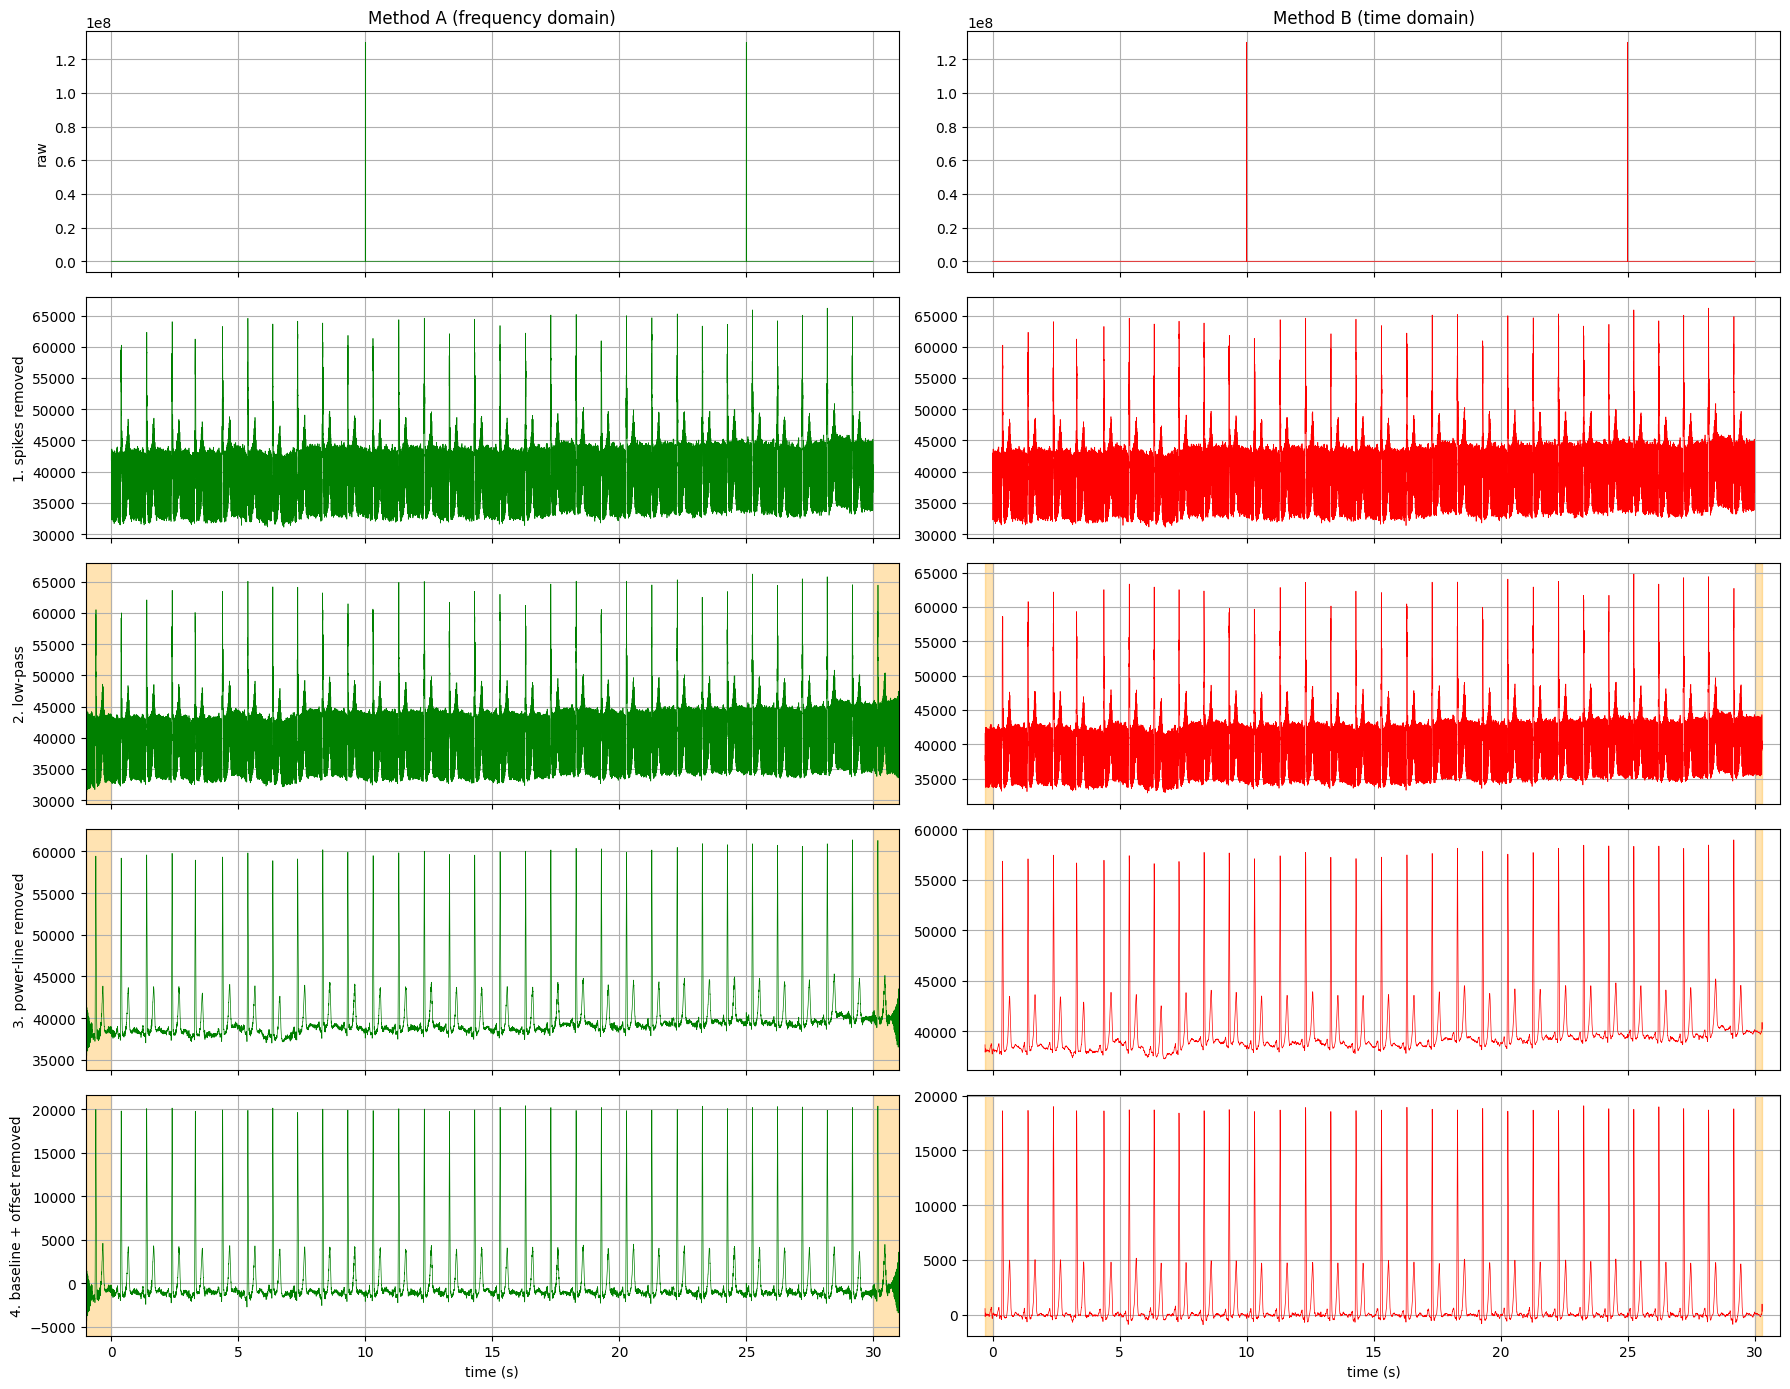

In [19]:
i = 5                                         # Ch6
rows_a = [ecg[i], ecg1[i], a2[i], a3[i], a4[i]]
rows_b = [ecg[i], ecg1[i], b2[i], b3[i], b4[i]]
names = ["raw", "1. spikes removed", "2. low-pass",
         "3. power-line removed", "4. baseline + offset removed"]

fig, axes = plt.subplots(5, 2, figsize=(18, 14), sharex=True)
for k in range(5):
    if k < 2:                                 # rows without padding
        axes[k, 0].plot(t, rows_a[k], linewidth=0.5, color="green")
        axes[k, 1].plot(t, rows_b[k], linewidth=0.5, color="red")
    else:                                     # rows with padding
        axes[k, 0].plot(t_pad_a, rows_a[k], linewidth=0.5,
                        color="green")
        axes[k, 1].plot(t_pad_b, rows_b[k], linewidth=0.5, color="red")
        axes[k, 0].axvspan(-pad_a / fs, 0, color="orange", alpha=0.3)
        axes[k, 0].axvspan(30, 30 + pad_a / fs, color="orange",
                           alpha=0.3)
        axes[k, 1].axvspan(-pad_b / fs, 0, color="orange", alpha=0.3)
        axes[k, 1].axvspan(30, 30 + pad_b / fs, color="orange",
                           alpha=0.3)
    axes[k, 0].set_ylabel(names[k])
axes[0, 0].set_title("Method A (frequency domain)")
axes[0, 1].set_title("Method B (time domain)")
axes[4, 0].set_xlim(-1, 31)
axes[4, 0].set_xlabel("time (s)")
axes[4, 1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

* **raw to 1:** the spikes are removed.
* **1 to 2:** the signal is a little smoother, but the 50 Hz noise (thick line) is still present.
* **2 to 3:** the 50 Hz noise is removed and the heartbeats become clear.
* **3 to 4:** the values are moved from about 39 000 to around 0, and the slow drift is removed.

### 13.1 Effect of each filter, Method A

Each row shows **one filter** applied to Ch6: the signal **before** the filter (grey) and **after**
the filter (green). Spike removal (step 1) is not shown here, so every row starts from the
spike-free signal. Only 9 to 11.5 s is shown (3 heartbeats), so that the effect of every filter
can be seen clearly. The padding is cut away for these plots.

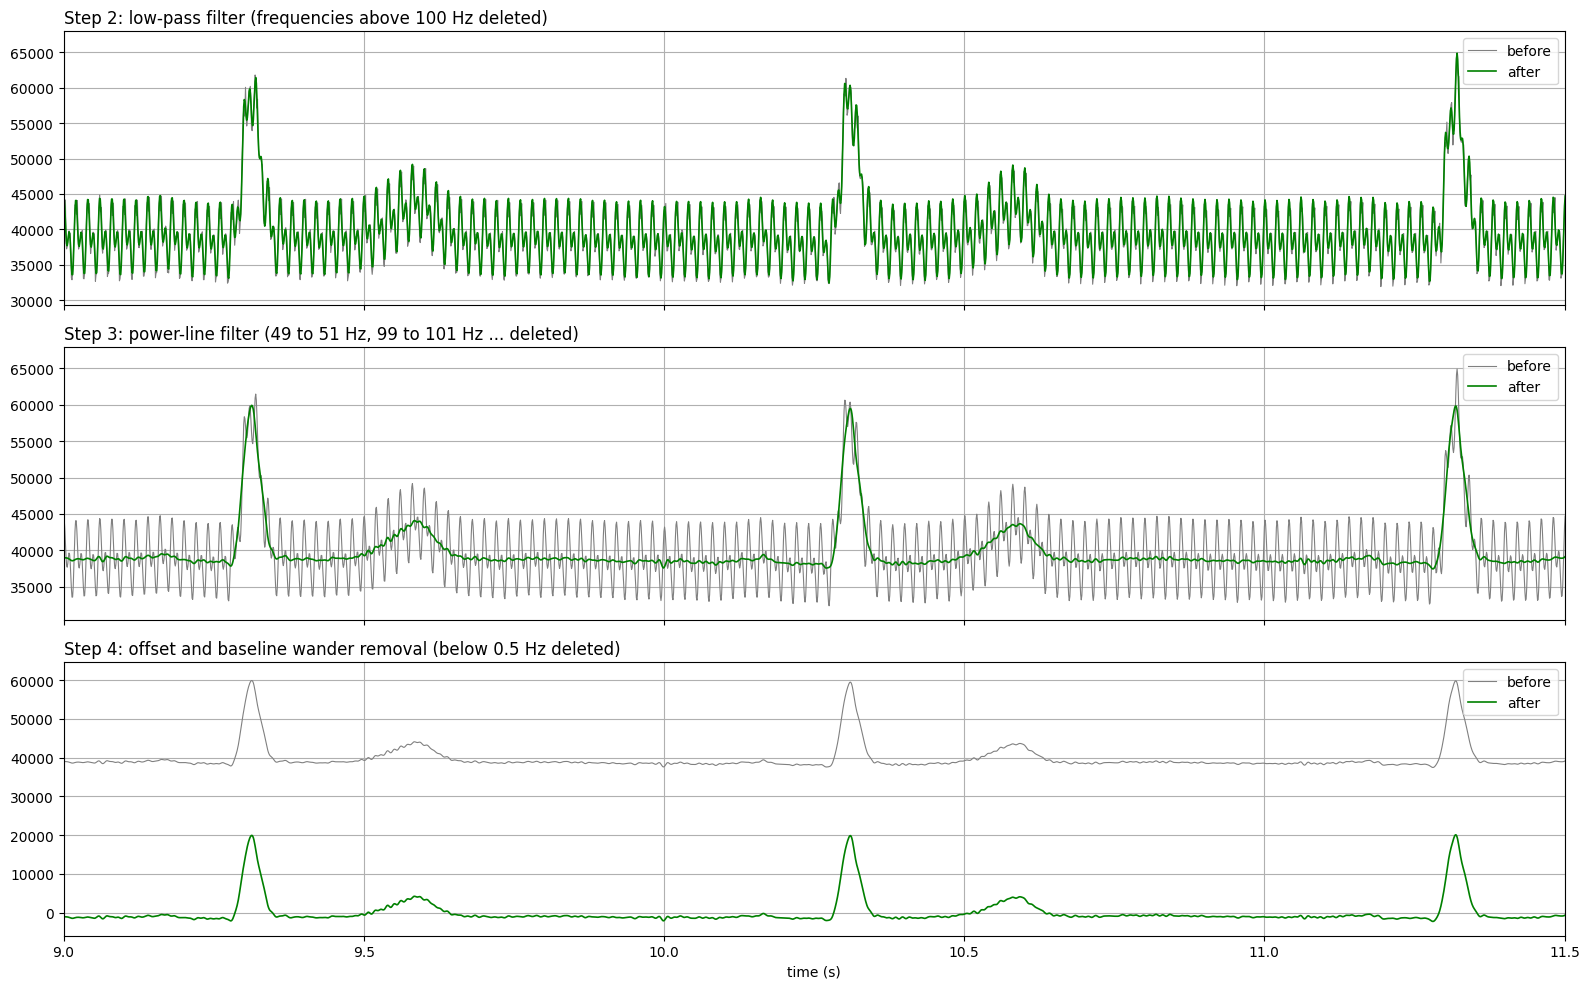

In [20]:
i = 5                                         # Ch6
befores = [ecg1[i], a2[i, pad_a:-pad_a], a3[i, pad_a:-pad_a]]
afters = [a2[i, pad_a:-pad_a], a3[i, pad_a:-pad_a], a4[i, pad_a:-pad_a]]
titles = [
    "Step 2: low-pass filter (frequencies above 100 Hz deleted)",
    "Step 3: power-line filter (49 to 51 Hz, 99 to 101 Hz ... deleted)",
    "Step 4: offset and baseline wander removal (below 0.5 Hz deleted)"]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
for k in range(3):
    axes[k].plot(t, befores[k], linewidth=0.8, color="grey",
                 label="before")
    axes[k].plot(t, afters[k], linewidth=1.2, color="green",
                 label="after")
    axes[k].set_title(titles[k], loc="left")
    axes[k].legend(loc="upper right")
axes[2].set_xlim(9, 11.5)
axes[2].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

* **Step 2:** the signal is only a little smoother, because most of the noise is the 50 Hz wave, which lies below 100 Hz.
* **Step 3:** the 50 Hz wave is removed, and P, QRS and T become clearly visible.
* **Step 4:** the whole signal is moved from about 39 000 down to around 0 (offset), and the slow drift is removed.

### 13.2 Effect of each filter, Method B

In Method B, step 4 consists of several operations, so every operation gets its own row.
Spike removal (step 1) is not shown here either.
Grey is the input of the operation, red is the output. In the two median filter rows, the
orange line is the output of the median filter (the estimated baseline), which is not the ECG itself.

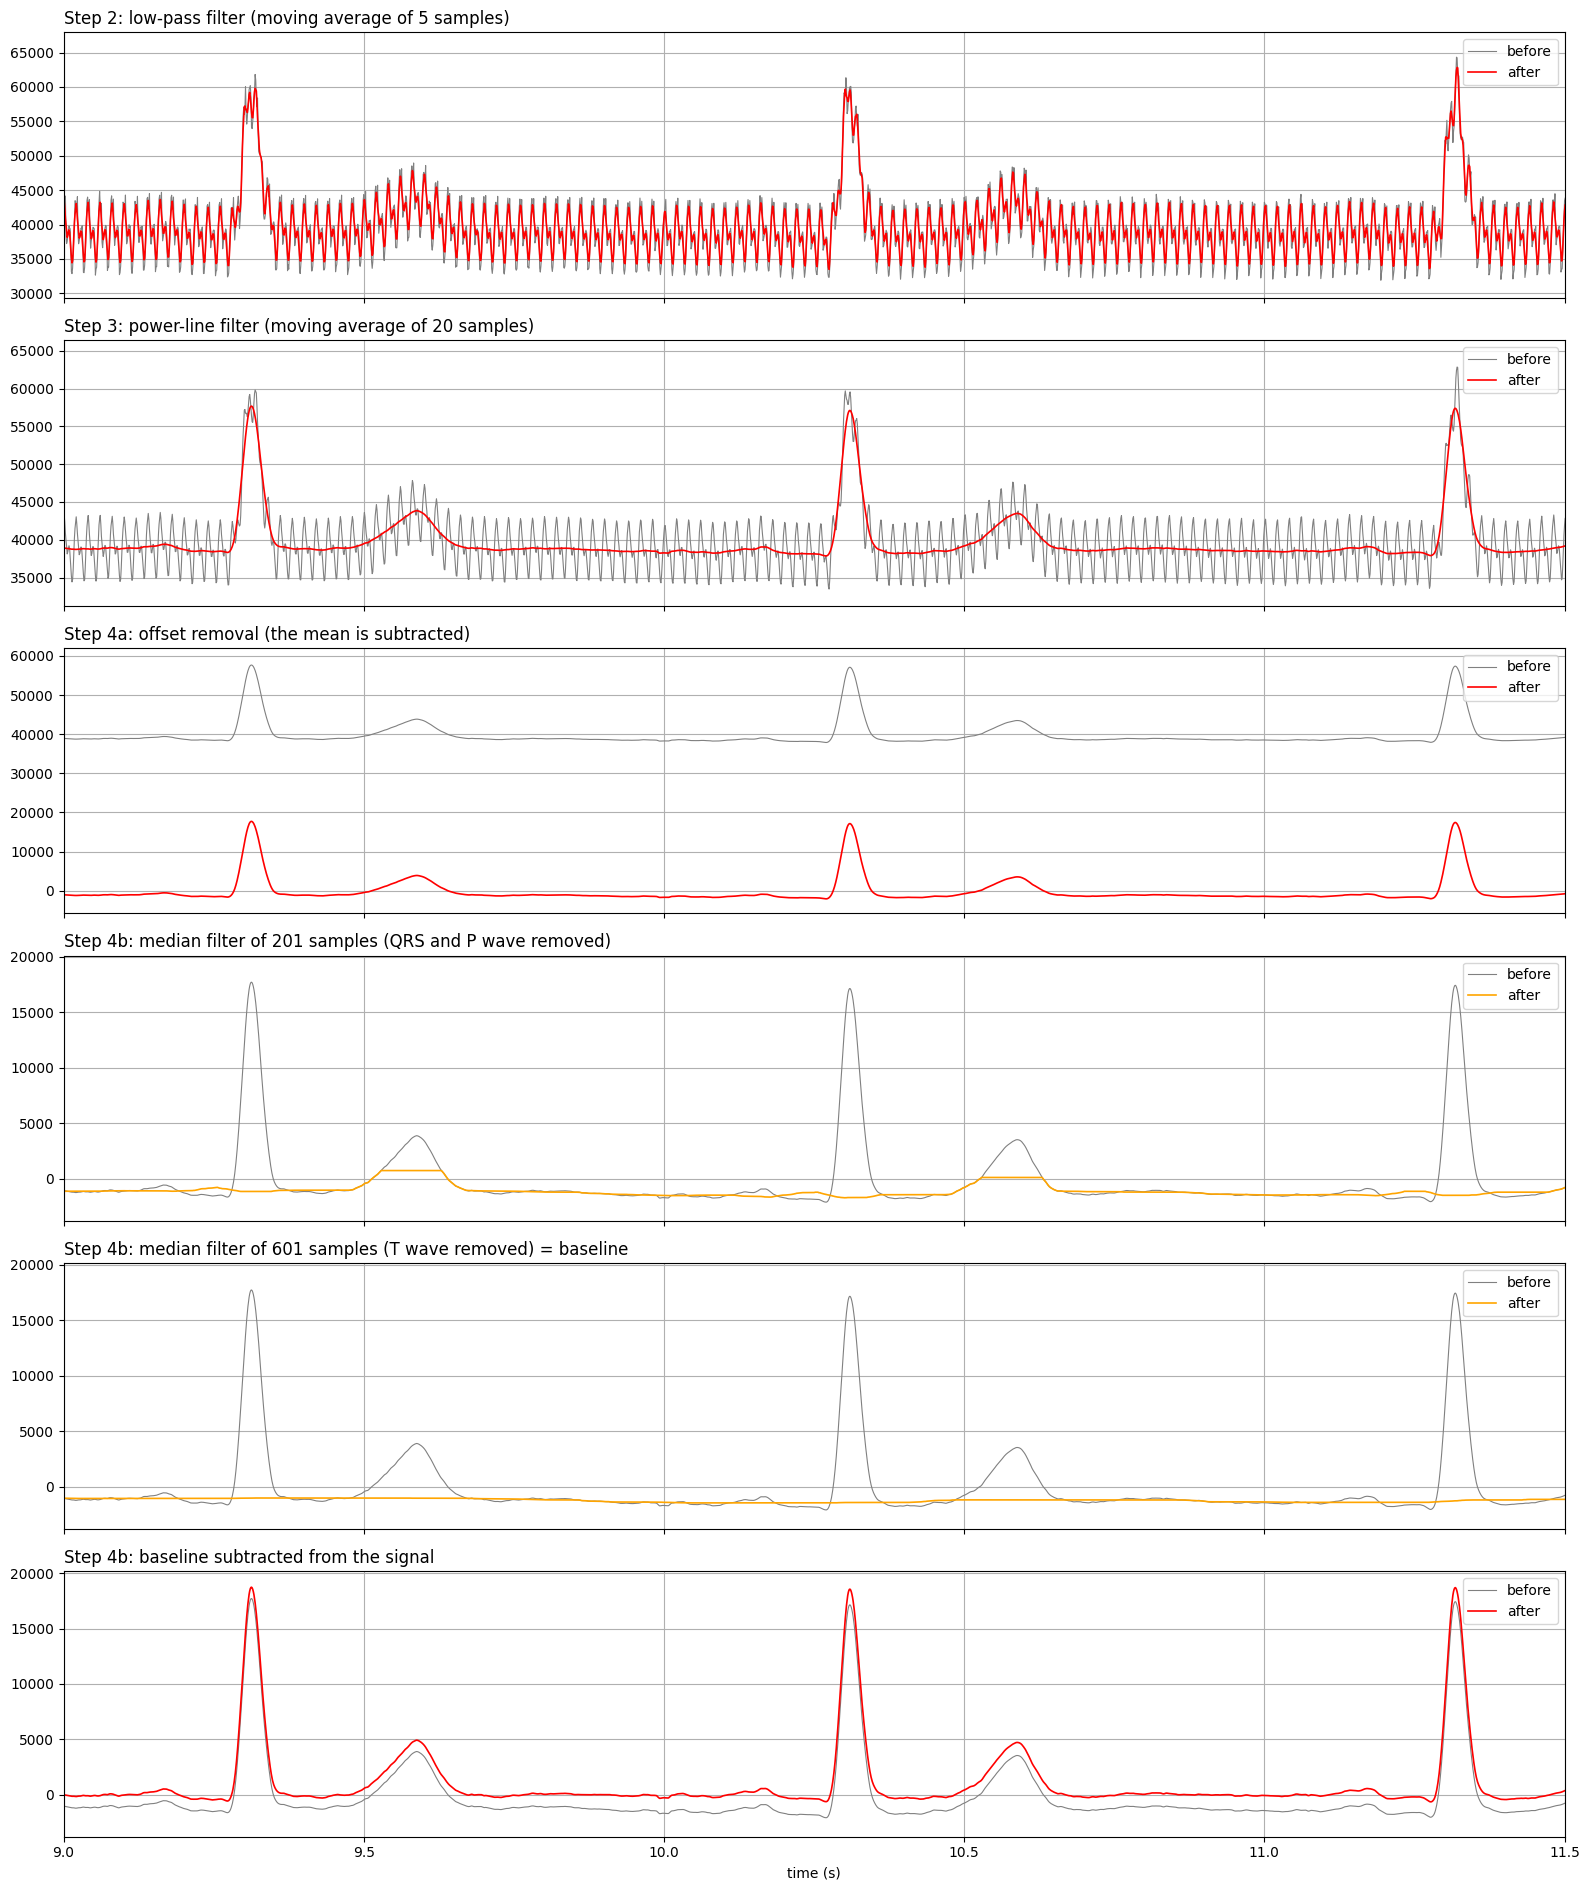

In [21]:
i = 5                                         # Ch6
x_offset = b3[i] - np.mean(b3[i])             # step 4a: offset removed
median_201 = median_filter(x_offset, 201)     # first median filter
# second median filter = baseline
baseline = median_filter(median_201, 601)

befores = [ecg1[i],
           b2[i, pad_b:-pad_b],
           b3[i, pad_b:-pad_b],
           x_offset[pad_b:-pad_b],
           x_offset[pad_b:-pad_b],
           x_offset[pad_b:-pad_b]]
afters = [b2[i, pad_b:-pad_b],
          b3[i, pad_b:-pad_b],
          x_offset[pad_b:-pad_b],
          median_201[pad_b:-pad_b],
          baseline[pad_b:-pad_b],
          b4[i, pad_b:-pad_b]]
colors = ["red", "red", "red", "orange", "orange", "red"]
titles = [
    "Step 2: low-pass filter (moving average of 5 samples)",
    "Step 3: power-line filter (moving average of 20 samples)",
    "Step 4a: offset removal (the mean is subtracted)",
    "Step 4b: median filter of 201 samples (QRS and P wave removed)",
    "Step 4b: median filter of 601 samples (T wave removed) = baseline",
    "Step 4b: baseline subtracted from the signal"]

fig, axes = plt.subplots(6, 1, figsize=(16, 19), sharex=True)
for k in range(6):
    axes[k].plot(t, befores[k], linewidth=0.8, color="grey",
                 label="before")
    axes[k].plot(t, afters[k], linewidth=1.2, color=colors[k],
                 label="after")
    axes[k].set_title(titles[k], loc="left")
    axes[k].legend(loc="upper right")
axes[5].set_xlim(9, 11.5)
axes[5].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

* **Step 2:** the 5-sample average makes the signal only a little smoother; the 50 Hz wave is still present.
* **Step 3:** the 20-sample average removes the 50 Hz wave completely; the QRS becomes a little lower and wider.
* **Step 4a:** the whole signal is moved down by its mean value (about 39 000), so it lies around 0.
* **Step 4b, 201 samples:** the median filter removes the narrow QRS and P wave, but the wider T wave is still present in the orange line.
* **Step 4b, 601 samples:** the second median filter also removes the T wave; the orange line now follows only the slow baseline.
* **Step 4b, subtraction:** the baseline is subtracted, so the line between the beats lies at 0.

## 14. Comparison of the two methods

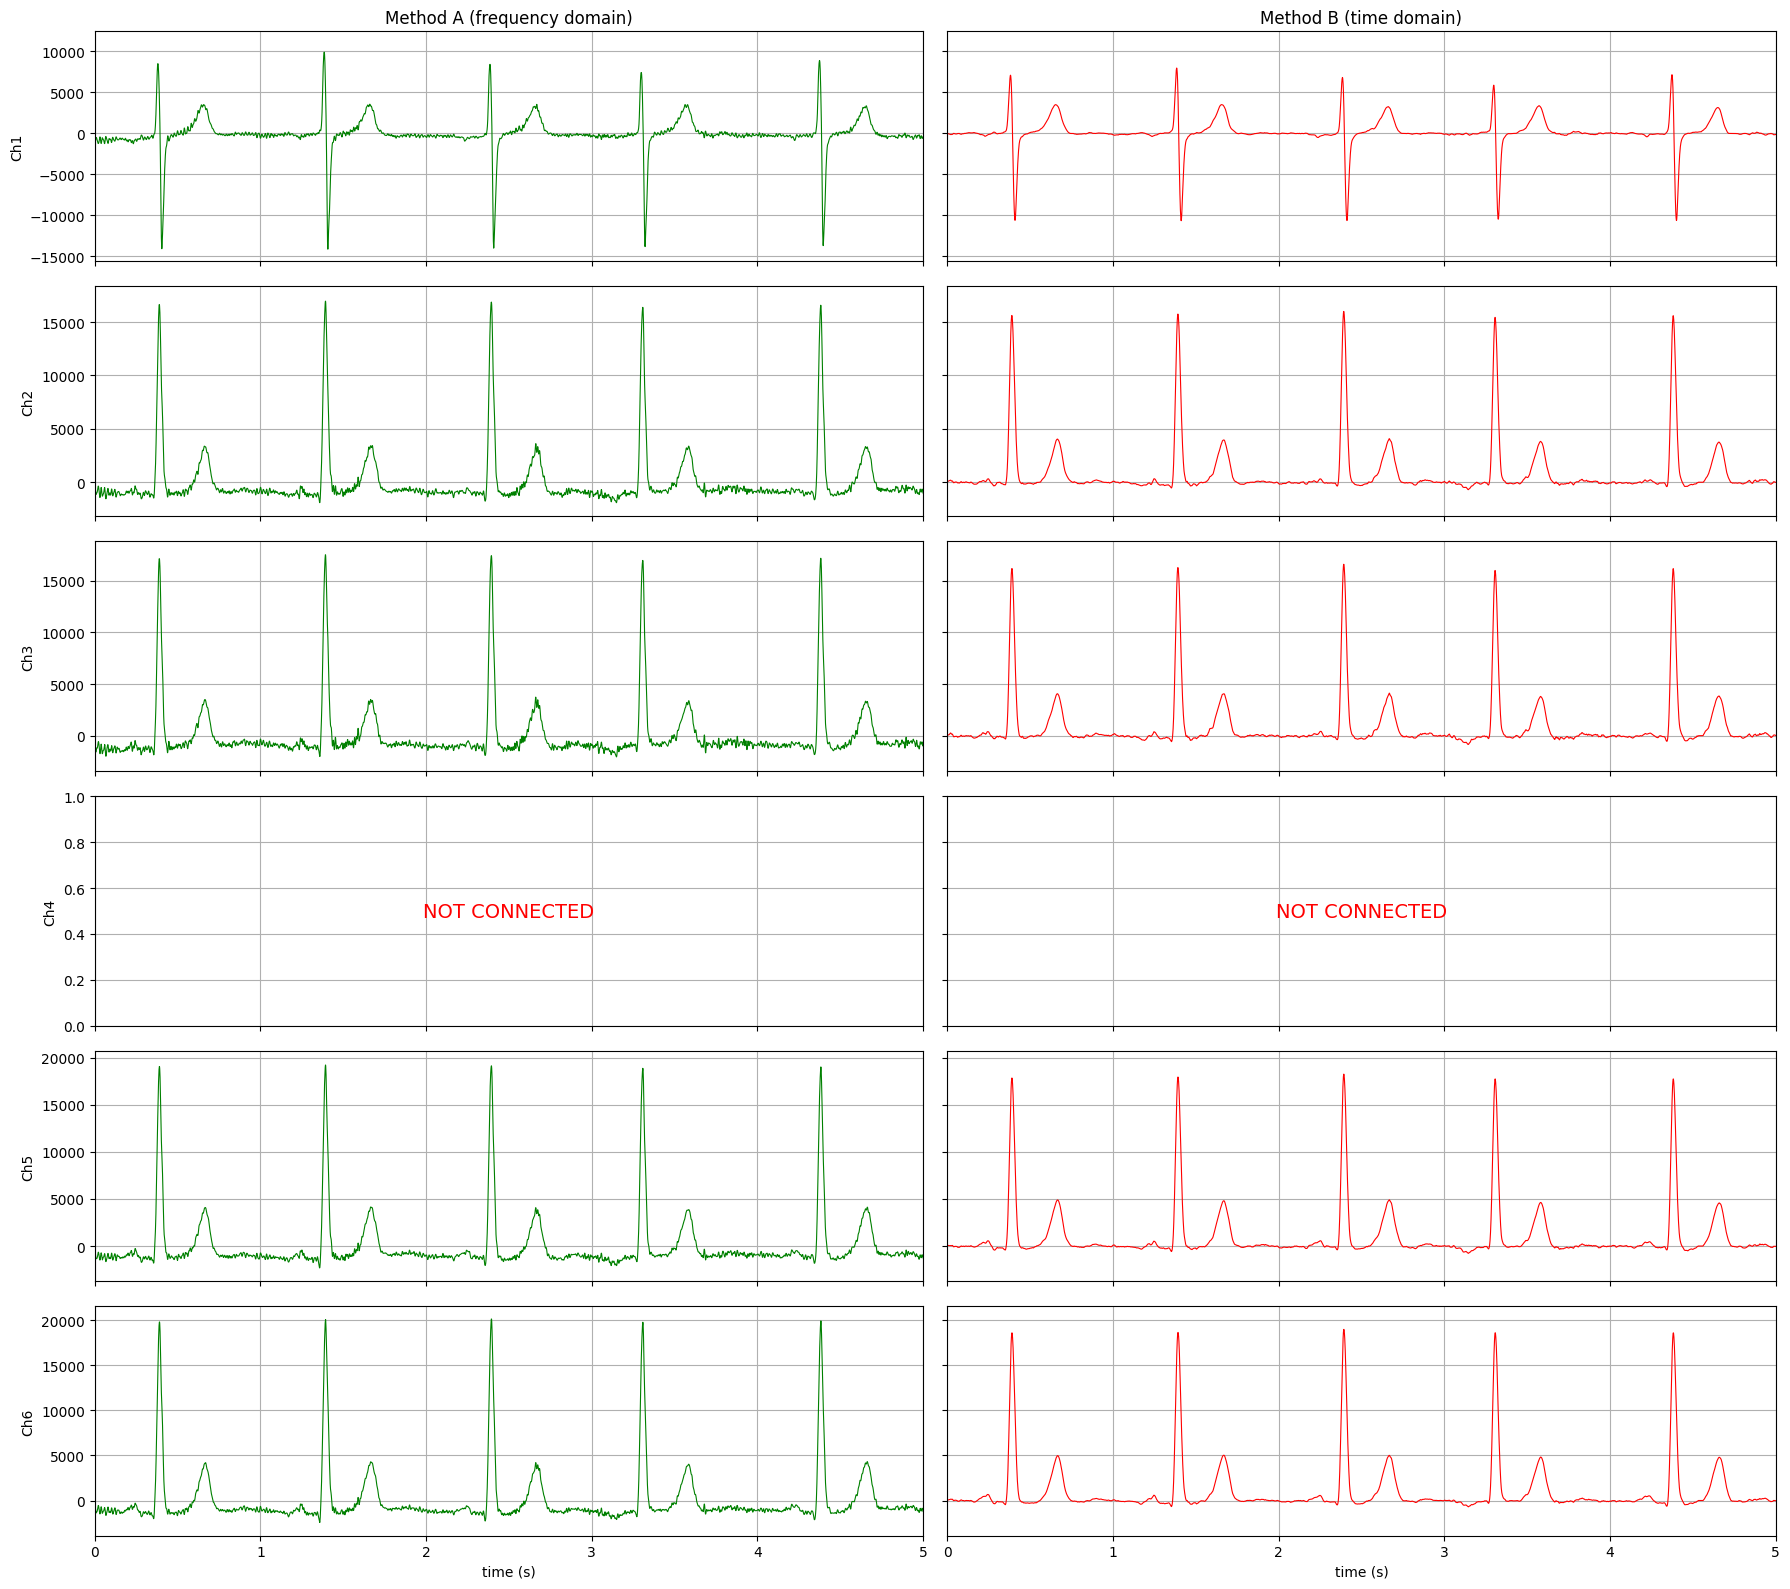

In [22]:
fig, axes = plt.subplots(6, 2, figsize=(18, 16),
                         sharex=True, sharey="row")
for i in range(6):
    if i == 3:                                # Ch4 is not connected
        for col in range(2):
            axes[i, col].text(0.5, 0.5, "NOT CONNECTED", color="red",
                              fontsize=14, ha="center", va="center",
                              transform=axes[i, col].transAxes)
    else:
        axes[i, 0].plot(t, ecg_a[i], linewidth=0.8, color="green")
        axes[i, 1].plot(t, ecg_b[i], linewidth=0.8, color="red")
    axes[i, 0].set_ylabel(ch_names[i])

axes[0, 0].set_title("Method A (frequency domain)")
axes[0, 1].set_title("Method B (time domain)")
# first 5 seconds = 5 heartbeats
axes[5, 0].set_xlim(0, 5)
axes[5, 0].set_xlabel("time (s)")
axes[5, 1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

Both methods show the same 5 heartbeats in every connected channel. In Method B the sharp
QRS peaks are a little lower and wider, and the line between the beats lies exactly at 0.

In [23]:
for i in [0, 1, 2, 4, 5]:
    print(ch_names[i], " R-peak A:", round(np.max(np.abs(ecg_a[i]))),
          " R-peak B:", round(np.max(np.abs(ecg_b[i]))))

Ch1  R-peak A: 14289  R-peak B: 10942
Ch2  R-peak A: 17373  R-peak B: 16175
Ch3  R-peak A: 17800  R-peak B: 16751
Ch5  R-peak A: 19570  R-peak B: 18324
Ch6  R-peak A: 20430  R-peak B: 19088


## 15. Long lead: every lead over the whole 30 s

For each lead, the raw signal, the Method A result and the Method B result are shown,
together with the number of detected heartbeats.

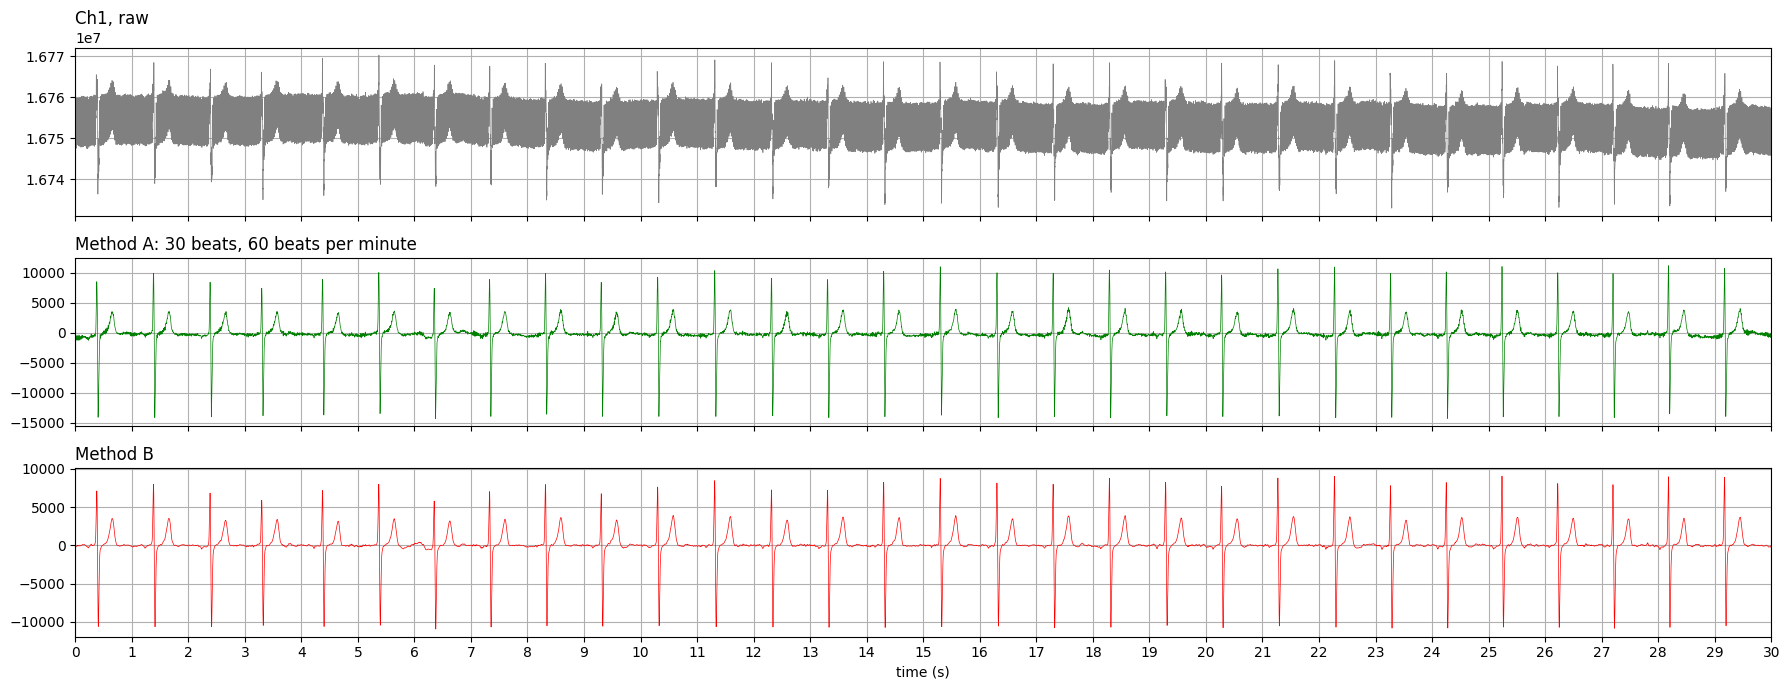

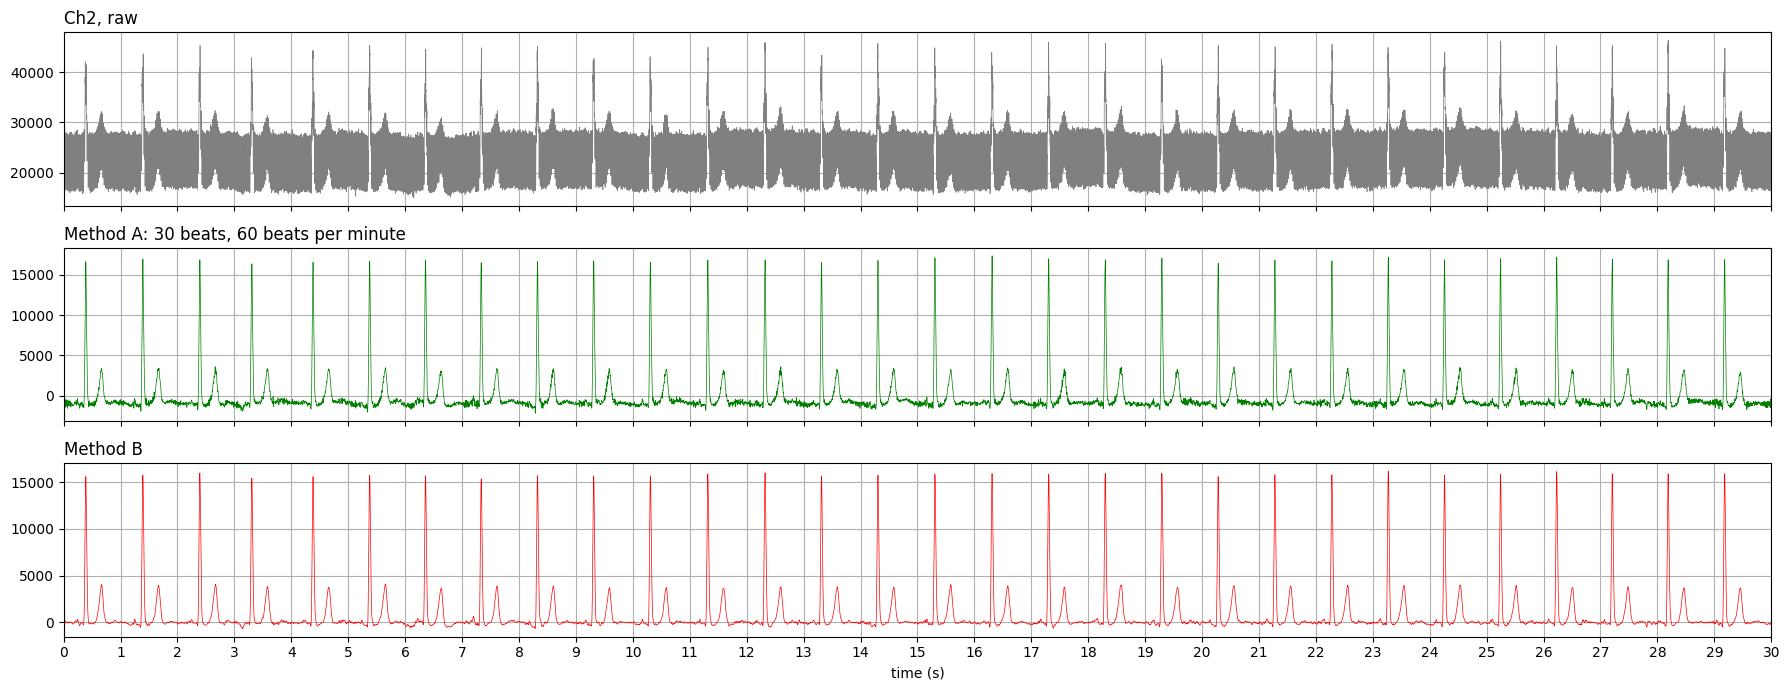

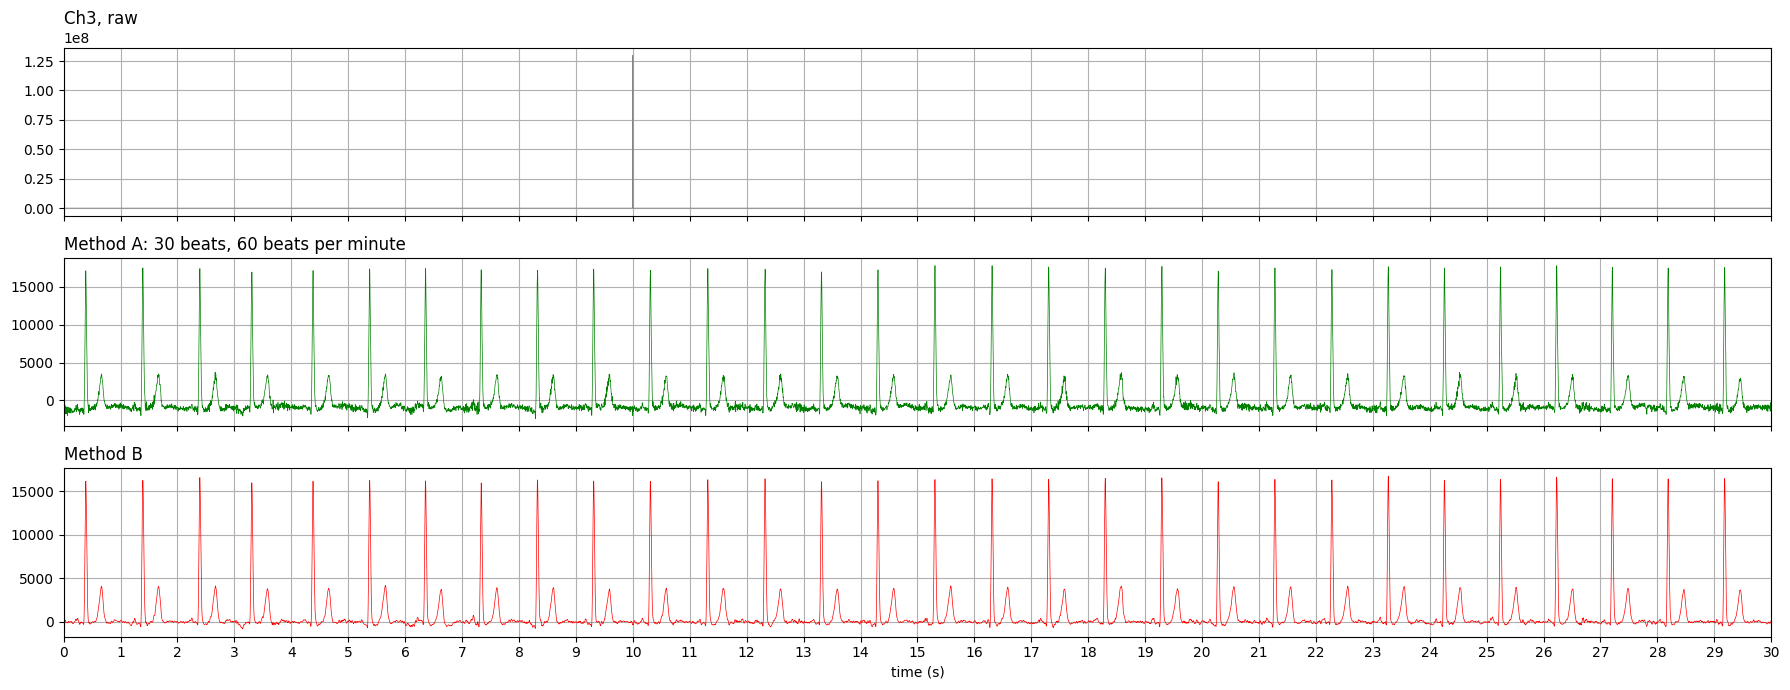

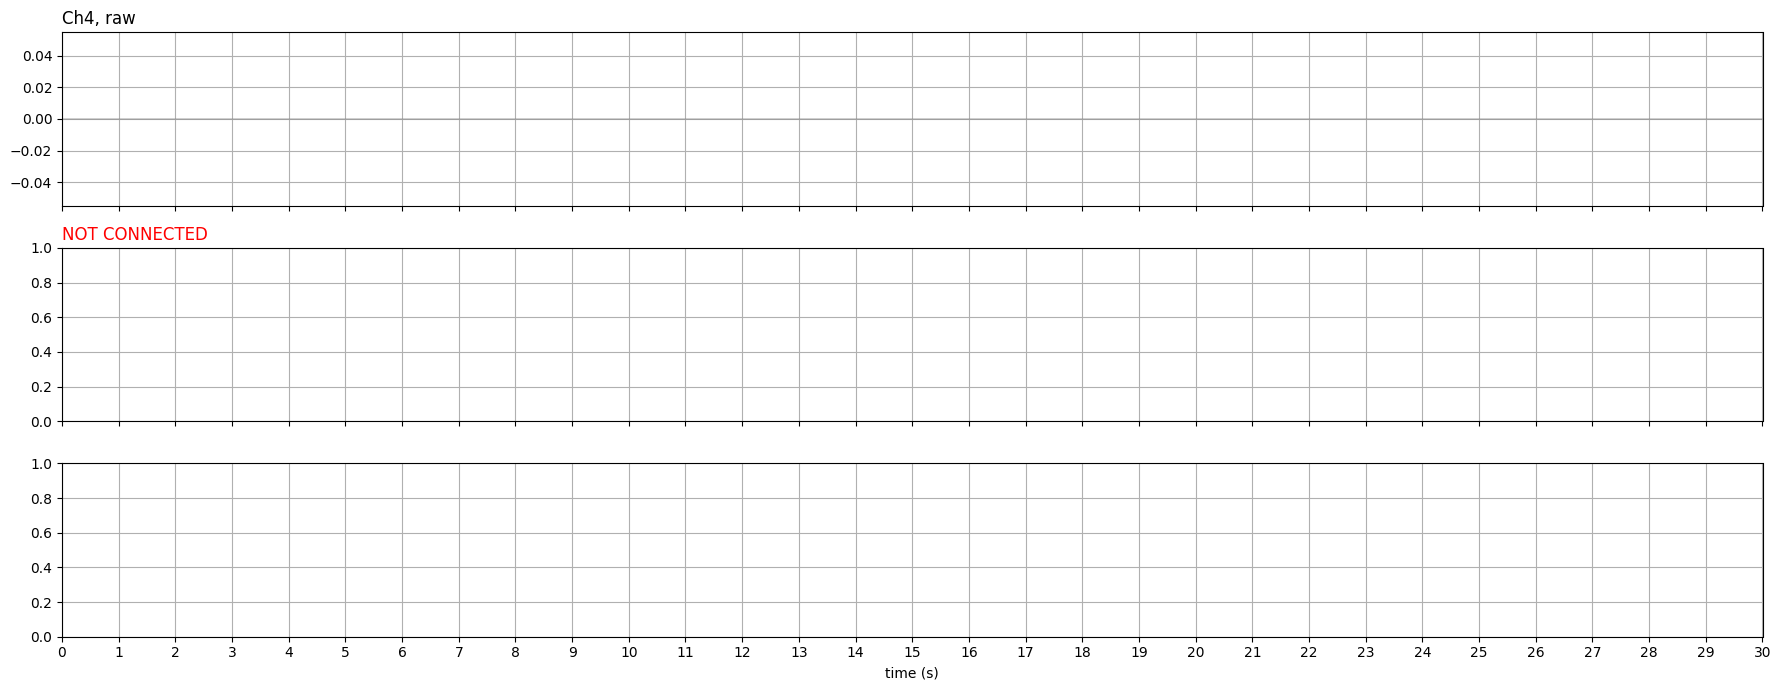

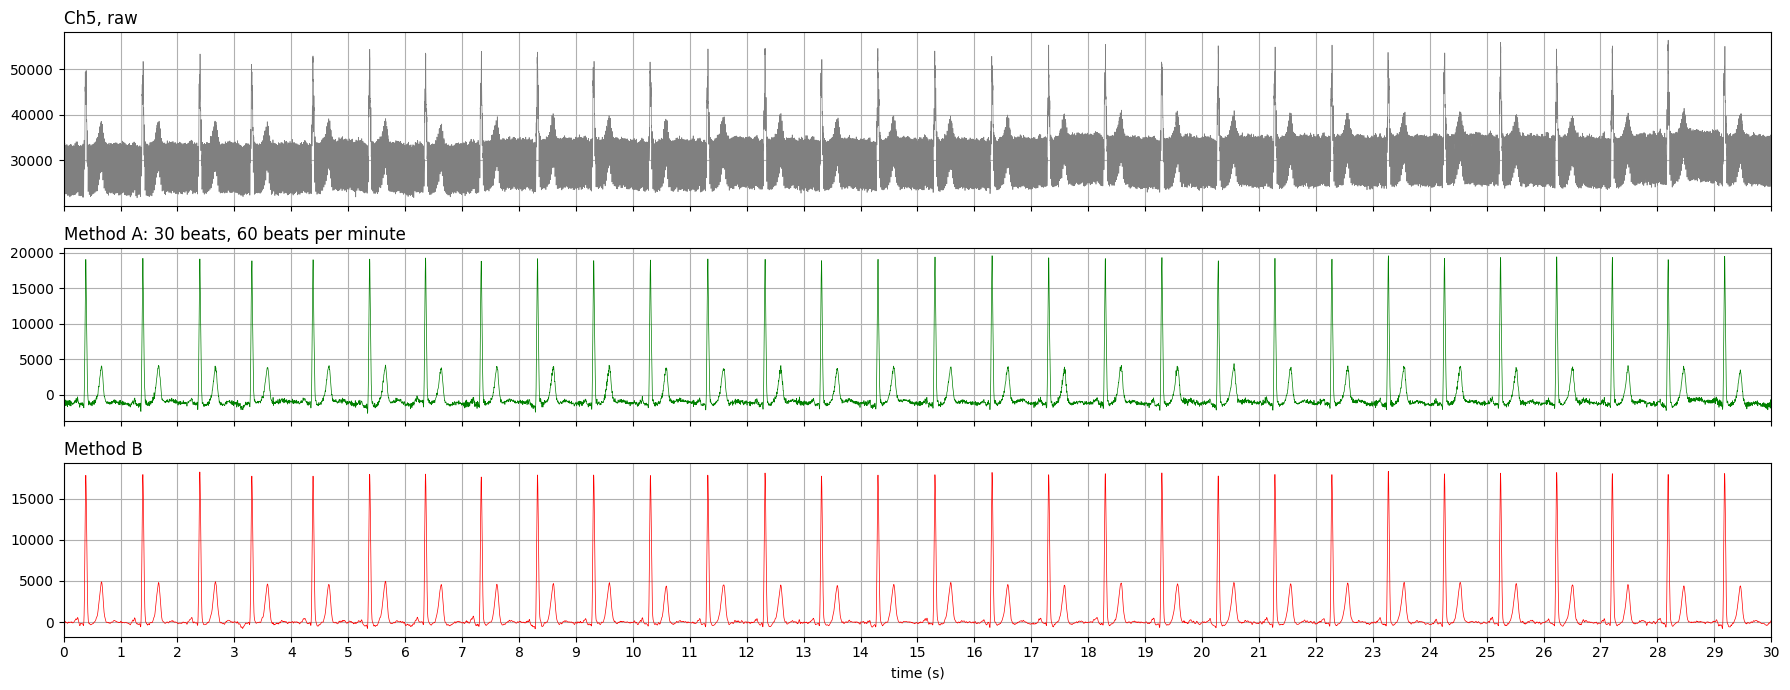

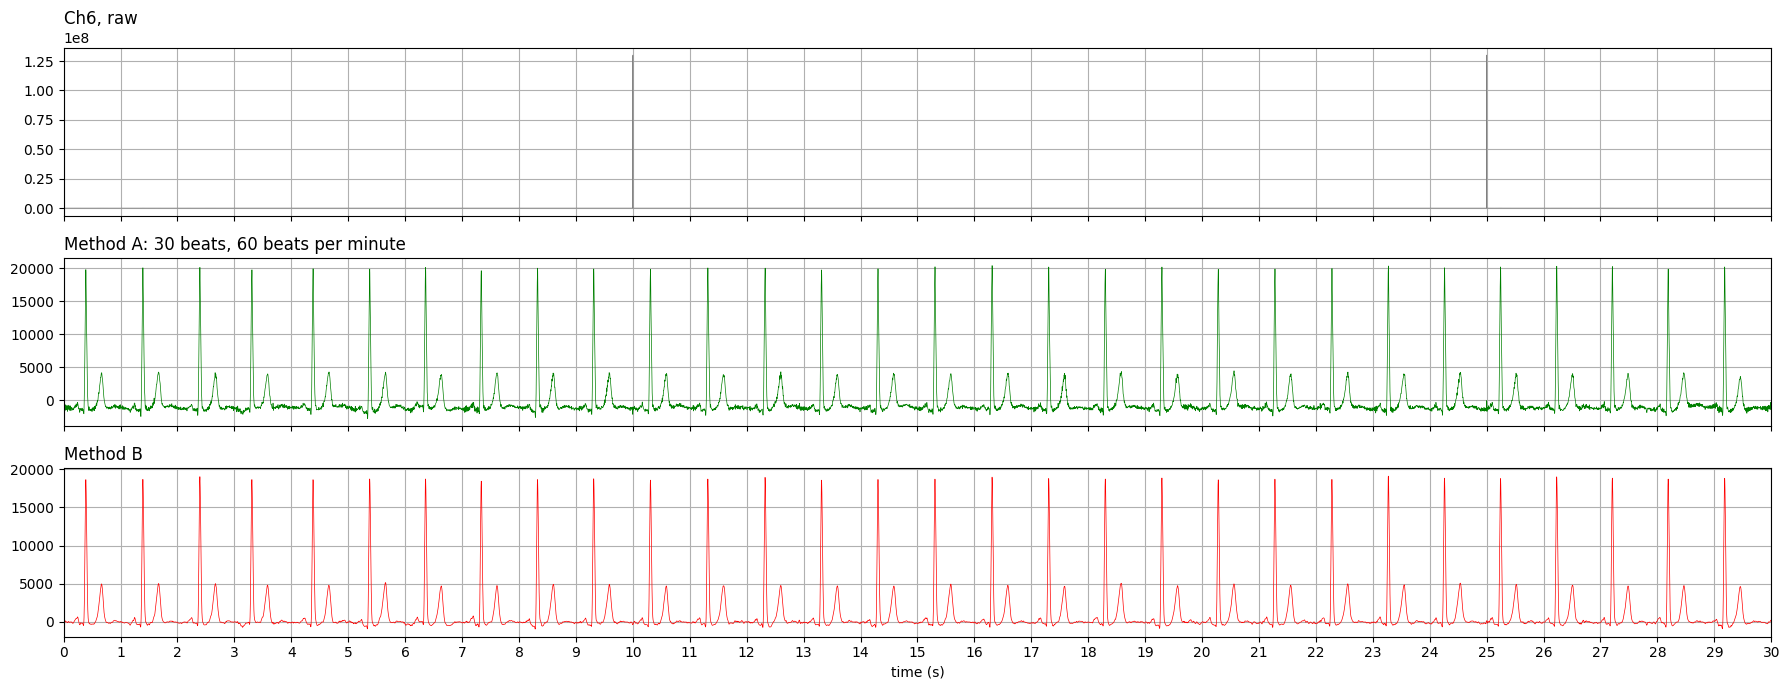

In [24]:
for i in range(6):
    fig, axes = plt.subplots(3, 1, figsize=(18, 7), sharex=True)
    axes[0].plot(t, ecg[i], linewidth=0.5, color="grey")
    axes[0].set_title(ch_names[i] + ", raw", loc="left")

    if i == 3:                                # Ch4 is not connected
        axes[1].set_title("NOT CONNECTED", loc="left", color="red")
    else:
        x = ecg_a[i]
        # if the QRS points down, the signal is turned upside down
        if np.abs(np.min(x)) > np.max(x):
            x = -x
        beats, _ = find_peaks(x, height=0.5 * np.max(x), distance=300)
        heart_rate = 60 / np.mean(np.diff(beats) / fs)

        axes[1].plot(t, ecg_a[i], linewidth=0.5, color="green")
        title = ("Method A: " + str(len(beats)) + " beats, "
                 + str(round(heart_rate)) + " beats per minute")
        axes[1].set_title(title, loc="left")
        axes[2].plot(t, ecg_b[i], linewidth=0.5, color="red")
        axes[2].set_title("Method B", loc="left")

    axes[2].set_xlim(0, 30)
    axes[2].set_xticks(range(31))
    axes[2].set_xlabel("time (s)")
    plt.tight_layout()
    plt.show()

## 16. Saving the cleaned signals

The cleaned signals are saved in a new `.mat` file, `ecgConditioningExample-processed.mat`,
which can be opened in MATLAB (`load("ecgConditioningExample-processed.mat")`) or in Python
(`scipy.io.loadmat`).
As in the original file, every column is one channel (30000 x 6). Ch4 (not connected) is saved as zeros.

| Variable | Content |
|----------|---------|
| `ecg_spike_removed` | signals after step 1 (spike removal) |
| `ecg_method_a` | final result of Method A (frequency domain) |
| `ecg_method_b` | final result of Method B (time domain) |
| `fs` | sampling frequency (1000 Hz) |
| `connected` | 1 for a connected channel, 0 for a channel that is not connected |

In [25]:
from scipy.io import savemat, loadmat

connected = np.array([1, 1, 1, 0, 1, 1])      # Ch4 is not connected

savemat("ecgConditioningExample-processed.mat", {
    # .T: one column per channel, as in the original file
    "ecg_spike_removed": ecg1.T,
    "ecg_method_a": ecg_a.T,
    "ecg_method_b": ecg_b.T,
    "fs": fs,
    "connected": connected,
})

# check: the saved file is loaded again
check = loadmat("ecgConditioningExample-processed.mat")
keys = ["ecg_spike_removed", "ecg_method_a", "ecg_method_b",
        "fs", "connected"]
for key in keys:
    print(key, "->", check[key].shape)

ecg_spike_removed -> (30000, 6)
ecg_method_a -> (30000, 6)
ecg_method_b -> (30000, 6)
fs -> (1, 1)
connected -> (1, 6)


## 17. Summary

| Step | Method A (frequency domain) | Method B (time domain) |
|------|-----------------------------|------------------------|
| 0. Disconnected channel | std = 0, the channel is skipped | same |
| 1. Spike removal | more than 5 widths outside the 1st to 99th percentile range, replaced by linear interpolation | same |
| Padding (K/2) | 1000 samples (kernel: one 0.5 Hz wave) | 300 samples (kernel: 601-sample median filter) |
| 2. Low-pass | frequencies above 100 Hz are deleted | average of 5 samples |
| 3. Power-line | 50, 100, 150 ... Hz are deleted | average of 20 samples |
| 4. Baseline and offset | frequencies below 0.5 Hz are deleted | the mean and the median baseline are subtracted |
| Padding removal | 1000 samples cut away on both sides | 300 samples cut away on both sides |

Both methods give almost the same ECG. Method A keeps the height of the sharp peaks better,
while Method B can also be used in real time.